## Tahap 4: Pemodelan Sentimen menggunakan IndoBERT
Notebook ini memuat data teks bersih dan menggunakan model pre-trained IndoBERT dari Hugging Face untuk mengklasifikasikan sentimen setiap tweet menjadi Positif, Netral, atau Negatif.

In [1]:
import pandas as pd

file_path = '../data/processed/cleaned_dataset_karhutla.csv'
df = pd.read_csv(file_path)
df = df.dropna(subset=['final_text'])
print(f"Data siap dimodelkan: {df.shape[0]} baris.")

Data siap dimodelkan: 2234 baris.


In [4]:
from transformers import pipeline

print("Mengunduh dan memuat model IndoBERT...")
sentiment_model = pipeline(
    "sentiment-analysis",
    model="mdhugol/indonesia-bert-sentiment-classification"
)
print("Model berhasil dimuat.")

/opt/homebrew/Caskroom/miniforge/base/envs/praktikum-ml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1109 10:32:25.475000 18634 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Mengunduh dan memuat model IndoBERT...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 36592.52it/s]


Model berhasil dimuat.


In [5]:
from tqdm import tqdm
tqdm.pandas()

def get_sentiment(text):
    try:
        result = sentiment_model(str(text)[:512])
        return result[0]['label']
    except:
        return "ERROR"

print("Memulai pelabelan sentimen...")
df['sentiment'] = df['final_text'].progress_apply(get_sentiment)

output_path = '../data/processed/sentiment_results_karhutla.csv'
df.to_csv(output_path, index=False)
print(f"Hasil disimpan di: {output_path}")

Memulai pelabelan sentimen...


100%|██████████| 2234/2234 [00:32<00:00, 69.50it/s]


Hasil disimpan di: ../data/processed/sentiment_results_karhutla.csv


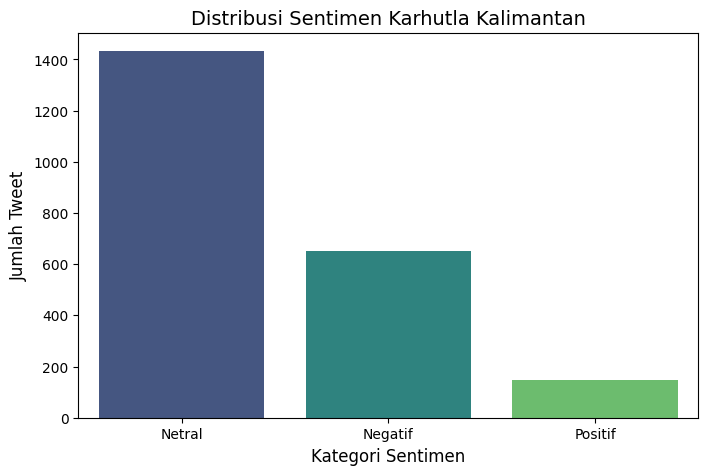

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Memetakan label asli ke teks deskriptif
label_mapping = {
    'LABEL_0': 'Positif',
    'LABEL_1': 'Netral',
    'LABEL_2': 'Negatif'
}

# Menerapkan pemetaan pada kolom sentimen
df['sentiment_label'] = df['sentiment'].map(label_mapping)

# Menghitung jumlah masing-masing sentimen yang telah dipetakan
sentiment_counts = df['sentiment_label'].value_counts()

plt.figure(figsize=(8, 5))
# Menggunakan 'hue' dan 'legend=False' sesuai saran FutureWarning
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, hue=sentiment_counts.index, palette='viridis', legend=False)
plt.title('Distribusi Sentimen Karhutla Kalimantan', fontsize=14)
plt.xlabel('Kategori Sentimen', fontsize=12)
plt.ylabel('Jumlah Tweet', fontsize=12)

fig_path = '../outputs/figures/sentiment_distribution.png'
plt.savefig(fig_path, bbox_inches='tight')
plt.show()